In [1]:
import seaborn as sns
import pandas as pd
import csv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from utils import significance,adjust_box_widths
from matplotlib.patches import PathPatch

In [2]:
df = pd.read_csv('Scores_CNORecall.csv')
print(df)
#print(df.loc[df['Control']=='y',:])

    Group  Cups Cups    Social Control
0       1  -0.267000  0.039194       y
1       2  -0.038333  0.001281       y
2       3  -0.148667  0.805800       n
3       4   0.129667  0.200933       y
4       5   0.141000  0.523100       y
5       6   0.163333 -0.129000       y
6       7   0.201667  0.434933       n
7       8  -0.092000  0.050400       y
8       9   0.109000  0.032667       y
9      10   0.065333  0.120000       y
10     11  -0.084667  0.127100       y
11     12   0.005000 -0.151000       y
12     13  -0.092233 -0.085533       y
13     14   0.318333  0.071839       y
14     15   0.004667  0.618314       n
15     16   0.189333  0.552948       n
16     17  -0.082000  0.642556       n
17     18  -0.213333  0.454819       n
18     19   0.176667  0.304194       n
19     20  -0.106000  0.605833       n
20     21  -0.062667  0.501333       n
21     22   0.062000  0.642831       n
22     23   0.045000  0.573267       n
23     24  -0.037467  0.703333       n
24     25  -0.091333  0.6

In [3]:
data = []

for el in df.drop("Group",axis=1).drop("Control",axis=1):
    for i,val in enumerate(df[el]):
        data.append([el,val,df.iloc[i].get('Control')])
        
newdf = (pd.DataFrame(data,columns=['Experimental Condition','Left preference','control']))
#print(newdf)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


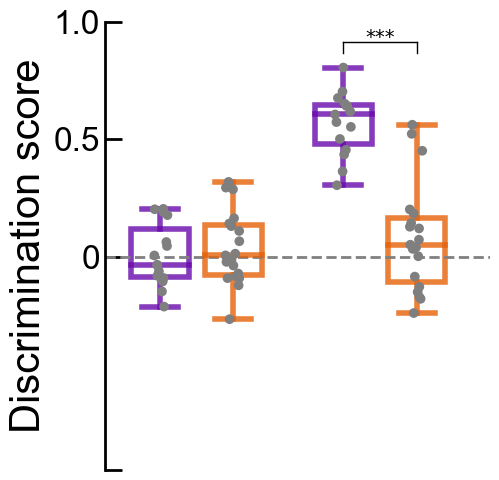

In [40]:
PROPS = {
    'boxprops':{'facecolor':'none', 'edgecolor':'mediumblue','alpha': 0.8},
    'medianprops':{'color':'cornflowerblue','alpha': 0.8},
    'whiskerprops':{'color':'cornflowerblue','alpha': 0.8},
    'capprops':{'color':'cornflowerblue','alpha': 0.8}
}

text_boxplot = ['***','***']
colors = ["C7","C7"]
colors_boxplot = ['#078f4f', "#680aab"]
colors_boxplot = ['#e66007', "#680aab"]
colors_boxplot = [ "#680aab",'#e66007']



ax = sns.stripplot(
    data=newdf,
    x='Experimental Condition',
    y='Left preference',
    hue='control',
    hue_order = ['n','y'],
    size=7,
    facecolors='none',
    edgecolors='black',
    palette=colors,
    jitter=0.09,
    dodge=True
)


locs = ["upper left"]
boxplot = sns.boxplot(
    data=newdf,
    x='Experimental Condition',
    y='Left preference',
    hue='control',
    hue_order = ['n','y'],
    palette=colors_boxplot,
    fliersize=0,
    linewidth=4,
    **PROPS
)
plt.axhline(linewidth=2, color='grey',ls='--')

data_ratio = 0.4016222222466667

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_linewidth(2)


#CHANGE BOXPLOT STYLE

box_patches = [patch for patch in boxplot.patches if type(patch) == matplotlib.patches.PathPatch]
if len(box_patches) == 0:  # in matplotlib older than 3.5, the boxes are stored in ax2.artists
    box_patches = boxplot.artists
    
num_patches = len(box_patches)
lines_per_boxplot = len(boxplot.lines) // num_patches

for i, patch in enumerate(box_patches):
    
    col = colors_boxplot[i%2]
    patch.set_edgecolor(col)
    patch.set_facecolor('None')
    
    for line in boxplot.lines[i * lines_per_boxplot: (i + 1) * lines_per_boxplot]:
        line.set_color(col)
        
        
#END CHANGE BOXPLOT STYLE

plt.legend([],[], frameon=False)

ax.set_xticklabels(['Cups','Social'], fontsize = 26)
ax.set_xticklabels([])
ax.set_xticks([])

ax.spines['left'].set_color('black')


ax.set_yticks([0,0.5,1], fontname='Arial')
ax.set_xlabel("",fontsize=20)
ax.set_ylabel('Discrimination score', fontsize = 30, fontname='Arial')

ax.set_yticks([-0.90999,0,0.5,1], fontname='Arial')
ax.set_yticklabels(['','0','0.5','1.0'],fontname='Arial')

ax.set_ylim([-0.90999,1])
ax.set_xlim([-0.5,1.6])
#significance(ax,1,data_ratio,newdf.loc[newdf['Experimental Condition']=='LTM']['Left preference'].max(),text=text_boxplot[1],offset=4,whisker=4)
significance(ax,1,data_ratio,newdf.loc[newdf['control']=='n']['Left preference'].max()+0.01,text=text_boxplot[1],offset=0.13,whisker=0.08)


fig = ax.get_figure()
adjust_box_widths(fig, 0.8)
fig.set_size_inches(5.1,4.9)
ax.tick_params(axis='y', which='major', direction='in',length=12, labelsize=24, width=2)

plt.tight_layout()
fig.tight_layout()
fig.savefig("Fig3b_ScoresHalves_DREADDsRecall.jpg",dpi=600,bbox_inches='tight')
plt.savefig('Fig3b_ScoresHalves_DREADDsRecall.eps', dpi=600, format='eps')

